Environment: the `etunc` kernel (pixi env `etunc`, with the repo installed editable).

# Coverage of the observational ET products

The ET products of the obs family (`scripts/prep_obs.py`): the ILAMB products (`il.PRODUCTS["et"]`, 0.5° or 1°)
and the gridded products of `GRIDDED_ET_PRODUCTS` (PML-V2.2, GLEAM v4.3, SiTHv2, 0.1°). Their records differ widely,
from 7 years (CLASS 2003-2009) to 46 (GLEAM v4.3a 1980-2025), and some have gaps over land (e.g. winter at high
latitudes, deserts). This notebook compares the spatial and temporal coverage of ET over land:

1. Gridcells and land area covered, on the native grids and on the pipeline's target grid
2. Maps of coverage on the native grids (valid months, complete years), and the valid land fraction by latitude
   and month
3. Timeseries of global and regional area-weighted valid land area and ET, and differences from `REF_ET`
4. Climatological ET maps and differences from `REF_ET`

Land is defined as in `scripts/prep_obs.py` (step 5): Natural Earth land by cell center, without Greenland and
Iceland, within `LAT_BNDS` (no Antarctica). "Complete year" follows step 4: a gridcell-year needs all 12 months.
A full 0.1° record is about 10 GB, so each product is reduced (zonal sums, counts, monthly fields on the target
grid) as it is loaded, and its native field is not kept.

In [1]:
import warnings

import dask
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

import etunc.config as cfg
import etunc.binning as binning
import etunc.grid as rg
import etunc.plotting as plotting
import etunc.temporal as temporal
import etunc.units as units
import etunc.load.ilamb as il
import etunc.load.obs as lo

warnings.filterwarnings("ignore", message="Input array is not C_CONTIGUOUS. Will affect performance.", category=UserWarning)

In [ ]:
TIME_SLICE = cfg.TIME_SLICE    # pipeline period, used for the coverage statistics and shaded in the timeseries
TARGET_RES = cfg.TARGET_RES    # pipeline target grid (deg)
PERIOD = temporal.format_time_period(TIME_SLICE)

ILAMB_ET = list(il.PRODUCTS["et"])  # CLASS, DOLCE, FLUXCOM, GLEAMv3.3a, MOD16A2, MODIS, WECANN
# Gridded ET products, as GRIDDED_ET_PRODUCTS of prep_obs.py: {label: (load_obs dataset, version, variable)}
GRIDDED_ET = {
    "PMLv2.2a_MODIS": ("pml", "V2.2a-MODIS", "ET"),
    "PMLv2.2c":       ("pml", "V2.2c", "ET"),
    "GLEAMv4.3a":     ("gleam", "v4.3a", "E"),
    "GLEAMv4.3b":     ("gleam", "v4.3b", "E"),
    "SiTHv2":         ("sith", "v2", "ET"),
}
PRODUCTS = [*ILAMB_ET, *GRIDDED_ET]
REF_ET = "GLEAMv4.3a"  # reference of the differences in sections 3-4: the longest record (1980-2025)
COLORS = {
    "CLASS": "tab:blue", "DOLCE": "tab:orange", "FLUXCOM": "tab:green", "GLEAMv3.3a": "tab:red",
    "MOD16A2": "tab:purple", "MODIS": "tab:brown", "WECANN": "tab:pink", "PMLv2.2a_MODIS": "tab:olive",
    "PMLv2.2c": "tab:cyan", "GLEAMv4.3a": "k", "GLEAMv4.3b": "tab:gray", "SiTHv2": "gold",
}

# Latitude bands for the regional averages: high-latitude (winter) gaps apart from the tropics
REGIONS = {
    "Global":                    cfg.LAT_BNDS,
    "NH high (50N-90N)":         slice(50, 90),
    "NH mid (23N-50N)":          slice(23, 50),
    "Tropics (23S-23N)":         slice(-23, 23),
    "SH extratropics (58S-23S)": slice(-58, -23),
}

: 

## Load monthly ET and reduce it

For each product, over its full record:
- `cov`: on the native grid, the zonal sums of the valid land area and of the area-weighted ET (time, lat), and,
  over `TIME_SLICE`, the valid months and complete years of each gridcell
- `mon1`: monthly ET on the target grid (land only; NaN where more than `NA_THRESH` of a target cell is missing)
- `ann1`: annual ET on the target grid over `TIME_SLICE`, as steps 4-8 of `prep_obs.py` compute it (annual means
  with the 12-month rule, land mask, ET outlier filter, conservative regridding with `NA_THRESH`)

In [ ]:
def month_start(da: xr.DataArray) -> xr.DataArray:
    """Time stamps set to the first of the month (datetime64), so all products share one monthly axis."""
    # ILAMB stamps mid-month, GLEAM and SiTHv2 the end of the month, PML the start
    time = pd.to_datetime(pd.DataFrame({"year": da.time.dt.year.values, "month": da.time.dt.month.values, "day": 1}))
    return da.assign_coords(time=time.values)


def load_et(p: str) -> xr.DataArray:
    """Monthly ET [W m-2] of product `p` over its full record, on its native grid within LAT_BNDS (lazy)."""
    if p in ILAMB_ET:
        da = units.flux_to_wm2(il.load_native("et", p, slice(None, None)))
    else:
        dataset, version, var = GRIDDED_ET[p]
        # Monthly totals -> kg m-2 s-1 -> W m-2, as in prep_obs.py step 3
        da = units.latent_heat_to_wm2(units.accumulation_to_flux(lo.load_obs(dataset, var, version=version)))
    # Pipeline domain without Antarctica; LAT_BNDS (-58) is a cell edge of every grid. One year per chunk, each
    # with the whole globe, as the regridder needs
    da = month_start(da.sel(lat=cfg.LAT_BNDS)).rename("et")
    return da.chunk({"time": 12, "lat": -1, "lon": -1})


def n_complete_years(v: xr.DataArray) -> xr.DataArray:
    """Years with all 12 months valid, per gridcell (the 12-month rule of prep_obs.py step 4)."""
    return (v.groupby("time.year").sum() == 12).sum("year")


def coverage(et: xr.DataArray, land: xr.DataArray, area: xr.DataArray) -> xr.Dataset:
    """Native-grid coverage of monthly ET: zonal sums over the full record, counts over TIME_SLICE."""
    valid = et.notnull() & land
    v = valid.sel(time=TIME_SLICE)
    return xr.Dataset({
        "zonal_area": xr.dot(valid, area, dim="lon"),                 # valid land area [km2] (time, lat)
        "zonal_et": xr.dot(et.where(valid, 0), area, dim="lon"),      # sum of ET x area (time, lat)
        "n_valid_months": v.sum("time"),                              # valid months in TIME_SLICE (lat, lon)
        "n_complete_years": n_complete_years(v),                      # complete years in TIME_SLICE (lat, lon)
    })


def to_target(da: xr.DataArray, label: str) -> xr.DataArray:
    """Conservative regridding to TARGET_RES as in prep_obs.py step 7, within LAT_BNDS (step 8)."""
    regridder = rg.bounded_conservative_regridder(rg.bounded_src_grid(da), TARGET_RES)
    return rg.on_grid(rg.regrid_with_na_thresh(da, regridder, cfg.NA_THRESH), TARGET_RES, label).sel(lat=cfg.LAT_BNDS)


land, area, cov, mon1, ann1 = {}, {}, {}, {}, {}
native, record, n_years = {}, {}, {}
for p in PRODUCTS:
    et = load_et(p)
    native[p] = rg.native_res(et)
    record[p] = f"{str(et.time.values[0])[:7]} to {str(et.time.values[-1])[:7]}"
    n_years[p] = len(temporal.complete_years(et.sel(time=TIME_SLICE)))  # years with 12 months in the time axis
    print(f"{p:15}: {native[p]:>16}, {record[p]} ({et.sizes['time']} months), {n_years[p]} complete years in {PERIOD}")

    # Land mask as in prep_obs.py step 5: Natural Earth land by cell center, without Greenland/Iceland
    land[p] = rg.landne_mask(et)
    # Land area of each native cell [km2], 0 over ocean
    area[p] = xr.DataArray(rg.cell_area(et.lat.values, et.lon.values) / 1e6, coords={"lat": et.lat, "lon": et.lon}) * land[p]
    et = et.where(land[p])

    # Coverage and monthly target-grid ET in one read of the native files
    cov[p], mon1[p] = dask.compute(coverage(et, land[p], area[p]), to_target(et, p))

    # Steps 4-8 over TIME_SLICE (a second read, of TIME_SLICE only)
    if n_years[p] == 0:
        print(f"{p}: no complete year in {PERIOD}, left out of the target-grid statistics")
        continue
    a = temporal.aggregate(et.sel(time=TIME_SLICE), "year", label=p)
    a = rg.mask_to_land(a, land[p], p)
    a = binning.drop_et_outliers(a, cfg.MIN_ANNUAL_ET, label=p)
    ann1[p] = to_target(a, p)
IN_SLICE = list(ann1)  # products with at least one complete year in TIME_SLICE

CLASS          :    0.5 x 0.5 deg, 2003-01 to 2009-12 (84 months), 7 complete years in 199501-201412
CLASS: annual means of 7 complete years; 11434 gridcell-years with partial (1-11) valid months, set to NaN
CLASS: 92 gridcell-years with annual ET < -2.0 W/m2 set to NaN (92 within LAT_BNDS; min -4.88)
DOLCE          :    0.5 x 0.5 deg, 2000-01 to 2009-12 (120 months), 10 complete years in 199501-201412
DOLCE: annual means of 10 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
DOLCE: 0 gridcell-years with annual ET < -2.0 W/m2 set to NaN
FLUXCOM        :    0.5 x 0.5 deg, 1980-01 to 2016-12 (444 months), 20 complete years in 199501-201412
FLUXCOM: annual means of 20 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN
FLUXCOM: 64 gridcell-years with annual ET < -2.0 W/m2 set to NaN (64 within LAT_BNDS; min -4.68)
GLEAMv3.3a     :    0.5 x 0.5 deg, 1980-01 to 2018-12 (468 months), 20 complete years in 199501-201412
GLEAMv3.3a: annual 

## 1. Gridcells and land area covered

Native gridcell counts are not comparable across resolutions (0.1°, 0.5°, 1°), so coverage is given as land
area [10⁶ km²]. Columns, over `TIME_SLICE`:
- `years`: complete calendar years of the product inside `TIME_SLICE`
- `any valid month`: land with at least one valid month
- `>=1 complete year`: land with at least one year of 12 valid months (needed for a climatological ET)
- `all years complete`: land with 12 valid months in every one of the product's years

In [ ]:
def land_km2(mask: xr.DataArray, cell_km2: xr.DataArray) -> float:
    """Land area [10^6 km2] of the cells in `mask`."""
    return float(cell_km2.where(mask).sum()) / 1e6


rows = {}
for p in PRODUCTS:
    c = cov[p]
    rows[p] = {
        "native res": native[p],
        "record": record[p],
        "years": n_years[p],
        "land cells": int(land[p].sum()),
        "land area": land_km2(land[p], area[p]),
        "any valid month": land_km2(c.n_valid_months > 0, area[p]),
        ">=1 complete year": land_km2(c.n_complete_years >= 1, area[p]),
        "all years complete": land_km2((c.n_complete_years == n_years[p]) & (n_years[p] > 0), area[p]),
    }
table_native = pd.DataFrame(rows).T.infer_objects()  # numeric columns back to numbers after the transpose
print(f"Native grids, {PERIOD}, land area in 10^6 km2")
table_native.round(2)

Native grids, 199501-201412, land area in 10^6 km2


,native res,record,years,land cells,land area,any valid month,>=1 complete year,all years complete
CLASS,0.5 x 0.5 deg,2003-01 to 2009-12,7,58648,132.15,119.67,118.99,104.63
DOLCE,0.5 x 0.5 deg,2000-01 to 2009-12,10,58648,132.15,123.74,123.74,123.74
FLUXCOM,0.5 x 0.5 deg,1980-01 to 2016-12,20,58648,132.15,117.92,117.92,117.92
GLEAMv3.3a,0.5 x 0.5 deg,1980-01 to 2018-12,20,58648,132.15,130.39,130.39,130.39
MOD16A2,0.5 x 0.5 deg,2000-01 to 2014-12,15,58648,132.15,112.22,112.22,112.10
MODIS,0.5 x 0.5 deg,2000-01 to 2013-12,14,58648,132.15,112.22,112.22,112.10
WECANN,1 x 1 deg,2007-01 to 2015-12,8,14661,132.10,128.82,128.81,128.78
PMLv2.2a_MODIS,0.1 x 0.1 deg,2000-03 to 2024-12,14,1464904,132.05,130.82,130.80,130.72
PMLv2.2c,0.1 x 0.1 deg,1982-01 to 2025-12,20,1464904,132.05,130.71,130.71,130.69
GLEAMv4.3a,0.1 x 0.1 deg,1980-01 to 2025-12,20,1464904,132.05,131.24,131.24,131.24


What the pipeline keeps: `ann1` above, and its climatology (step 10) over the product's complete years in
`TIME_SLICE`. A target gridcell has a climatological ET if it has at least one valid year. Land area on the
target grid is fractional Natural Earth land (`rg.land_area`), so coastal cells count only their land part.

In [ ]:
clim1 = {p: temporal.aggregate(ann1[p], "clim", label=p) for p in IN_SLICE}

# Land area [km2] of each target cell, and the land the pipeline considers (no Greenland/Iceland)
land_area1 = rg.land_area(clim1[REF_ET])
land_area1 = land_area1.where(rg.greenland_mask(land_area1), 0)

CLASS: climatology of 7 years; 576 gridcells have missing years (fewest valid years: 1)
DOLCE: climatology of 10 years; 0 gridcells have missing years
FLUXCOM: climatology of 20 years; 0 gridcells have missing years
GLEAMv3.3a: climatology of 20 years; 0 gridcells have missing years
MOD16A2: climatology of 15 years; 16 gridcells have missing years (fewest valid years: 1)
MODIS: climatology of 14 years; 16 gridcells have missing years (fewest valid years: 1)
WECANN: climatology of 8 years; 5 gridcells have missing years (fewest valid years: 7)
PMLv2.2a_MODIS: climatology of 14 years; 21 gridcells have missing years (fewest valid years: 1)
PMLv2.2c: climatology of 20 years; 3 gridcells have missing years (fewest valid years: 11)
GLEAMv4.3a: climatology of 20 years; 2 gridcells have missing years (fewest valid years: 19)
GLEAMv4.3b: climatology of 12 years; 1 gridcells have missing years (fewest valid years: 11)
SiTHv2: climatology of 20 years; 0 gridcells have missing years


In [ ]:
valid1 = {p: clim1[p].notnull() for p in IN_SLICE}
valid1["all products"] = xr.concat([valid1[p] for p in IN_SLICE], "p").all("p")

# Target gridcells with a climatological ET, and their land area per region
table_1deg = pd.DataFrame({
    p: {"gridcells": int(v.sum()), **{r: land_km2(v.sel(lat=b), land_area1.sel(lat=b)) for r, b in REGIONS.items()}}
    for p, v in valid1.items()
}).T.astype({"gridcells": int})
region_land = pd.Series({r: float(land_area1.sel(lat=b).sum()) / 1e6 for r, b in REGIONS.items()})
print(f"{rg.grid_tag(TARGET_RES)} target grid, {PERIOD}: gridcells and land area [10^6 km2] with a climatological ET")
print("Land area of each region [10^6 km2]:", region_land.round(1).to_dict())
display(table_1deg.round(1))
print("Percent of each region's land area")
display((100 * table_1deg[list(REGIONS)] / region_land).round(0))

1deg target grid, 199501-201412: gridcells and land area [10^6 km2] with a climatological ET
Land area of each region [10^6 km2]: {'Global': 132.1, 'NH high (50N-90N)': 29.4, 'NH mid (23N-50N)': 42.5, 'Tropics (23S-23N)': 48.5, 'SH extratropics (58S-23S)': 11.6}


,gridcells,Global,NH high (50N-90N),NH mid (23N-50N),Tropics (23S-23N),SH extratropics (58S-23S)
CLASS,13079,119.2,25.3,39.5,44.1,10.3
DOLCE,13760,122.8,26.7,40.2,45.1,10.8
FLUXCOM,13145,113.8,27.8,33.6,41.4,11.0
GLEAMv3.3a,14463,126.9,28.1,41.2,46.4,11.2
MOD16A2,12451,108.9,26.7,30.6,40.6,10.9
MODIS,12451,108.9,26.7,30.6,40.6,10.9
WECANN,14173,126.0,27.6,41.2,46.2,11.1
PMLv2.2a_MODIS,14464,127.4,28.2,41.5,46.6,11.2
PMLv2.2c,14441,127.4,28.1,41.5,46.6,11.2
GLEAMv4.3a,14510,127.4,28.3,41.4,46.5,11.2


Percent of each region's land area


,Global,NH high (50N-90N),NH mid (23N-50N),Tropics (23S-23N),SH extratropics (58S-23S)
CLASS,90.0,86.0,93.0,91.0,89.0
DOLCE,93.0,91.0,95.0,93.0,93.0
FLUXCOM,86.0,95.0,79.0,85.0,95.0
GLEAMv3.3a,96.0,96.0,97.0,96.0,96.0
MOD16A2,82.0,91.0,72.0,84.0,94.0
MODIS,82.0,91.0,72.0,84.0,94.0
WECANN,95.0,94.0,97.0,95.0,96.0
PMLv2.2a_MODIS,97.0,96.0,98.0,96.0,97.0
PMLv2.2c,96.0,96.0,98.0,96.0,97.0
GLEAMv4.3a,96.0,96.0,97.0,96.0,97.0


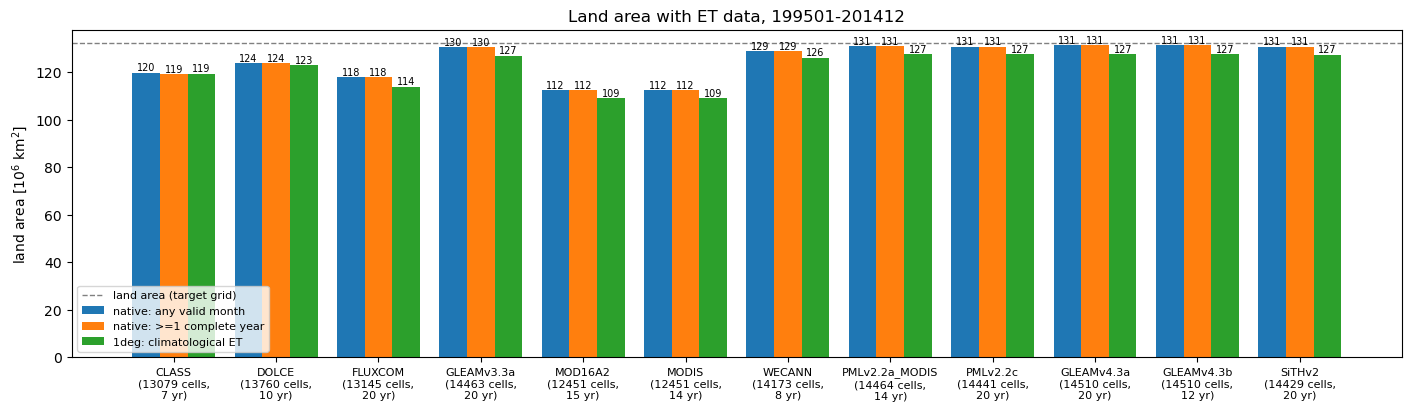

In [ ]:
# Land area covered by each product: native grid (any valid month, >=1 complete year) and target grid
kinds = {
    "native: any valid month": table_native["any valid month"],
    "native: >=1 complete year": table_native[">=1 complete year"],
    f"{rg.grid_tag(TARGET_RES)}: climatological ET": table_1deg["Global"].reindex(PRODUCTS),
}
fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
x, width = np.arange(len(PRODUCTS)), 0.27
for i, (kind, values) in enumerate(kinds.items()):
    bars = ax.bar(x + (i - 1) * width, values[PRODUCTS].astype(float), width, label=kind)
    ax.bar_label(bars, fmt="%.0f", fontsize=7)
# Target gridcell counts and years in TIME_SLICE under the product names
ax.set_xticks(x, [f"{p}\n({table_1deg['gridcells'].get(p, 0)} cells,\n{n_years[p]} yr)" for p in PRODUCTS], fontsize=8)
ax.axhline(region_land["Global"], color="gray", ls="--", lw=1, label="land area (target grid)")
ax.set_ylabel("land area [10$^6$ km$^2$]")
ax.set_title(f"Land area with ET data, {PERIOD}")
ax.legend(fontsize=8, loc="lower left")
plt.show()

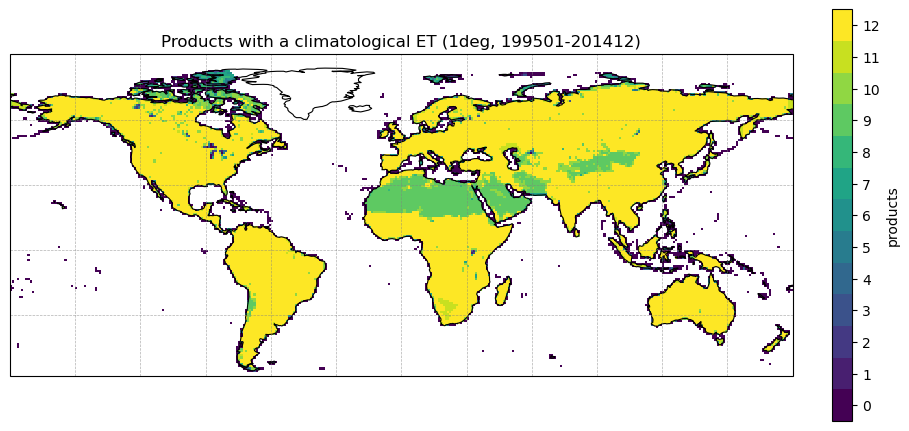

In [ ]:
# Number of products with a climatological ET in each target cell
n_products = sum(valid1[p].astype(int) for p in IN_SLICE).where(land_area1 > 0)
n = len(IN_SLICE)

fig, axs = plotting.facets(1, ncols=1, maps=True, panel_size=(9, 4.2))
n_products.plot.pcolormesh(ax=axs[0], transform=ccrs.PlateCarree(), cmap=plt.get_cmap("viridis", n + 1),
                           vmin=-0.5, vmax=n + 0.5, cbar_kwargs={"label": "products", "ticks": range(n + 1)})
axs[0].set_title(f"Products with a climatological ET ({rg.grid_tag(TARGET_RES)}, {PERIOD})")
plotting.map_ax(axs[0], cfg.LAT_BNDS)
plt.show()

## 2. Maps of coverage on the native grids

Fraction of each product's months in `TIME_SLICE` with valid data, and fraction of its years that are complete.
A product's months/years are only those inside both its record and `TIME_SLICE`.

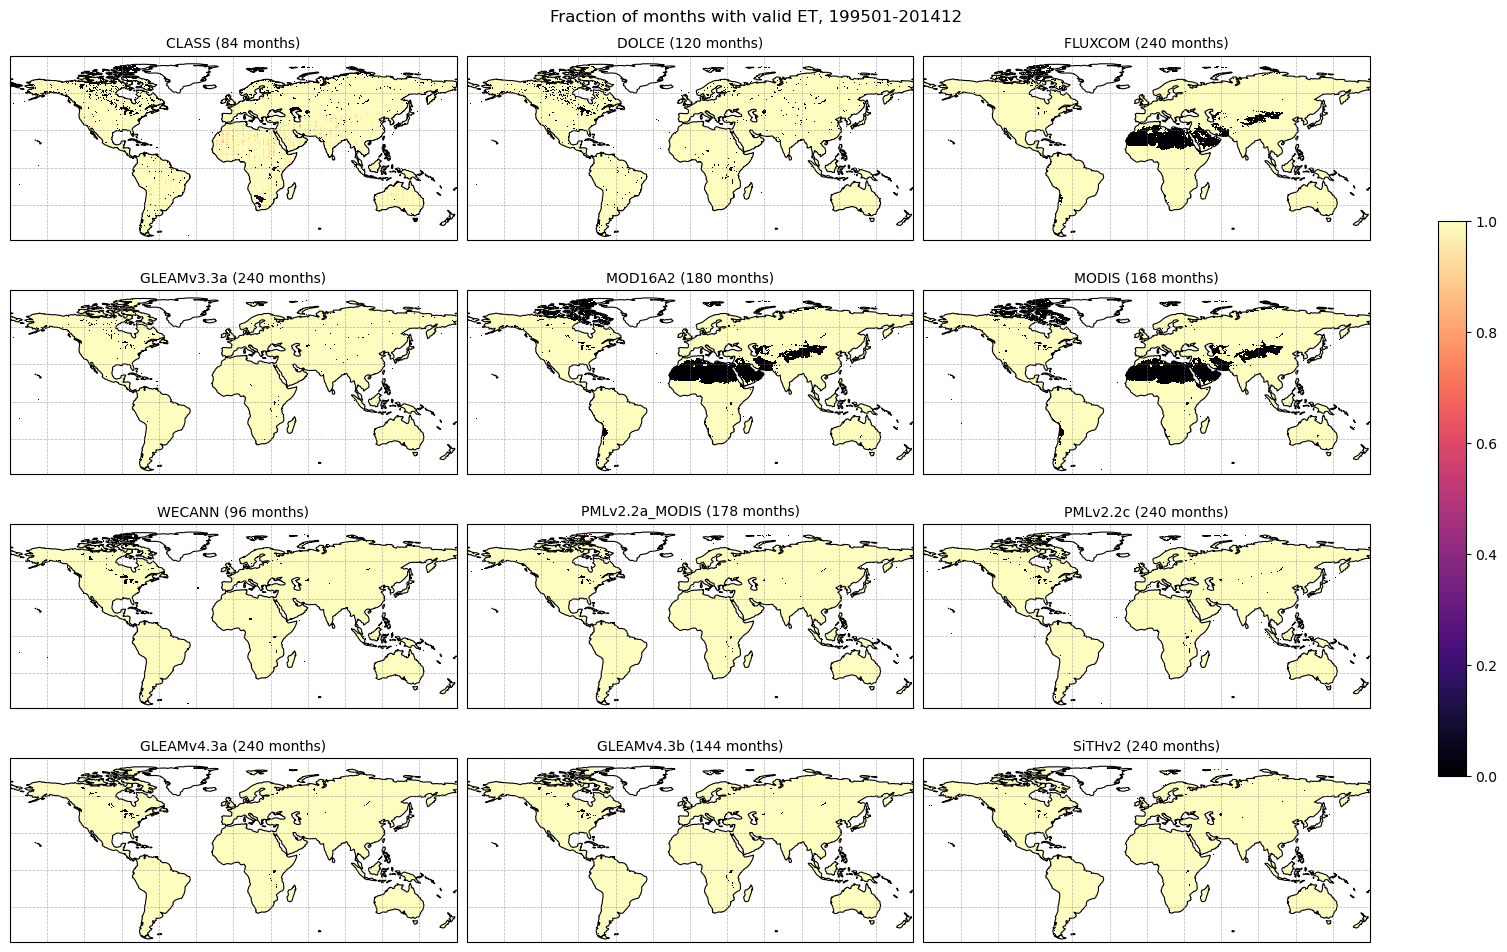

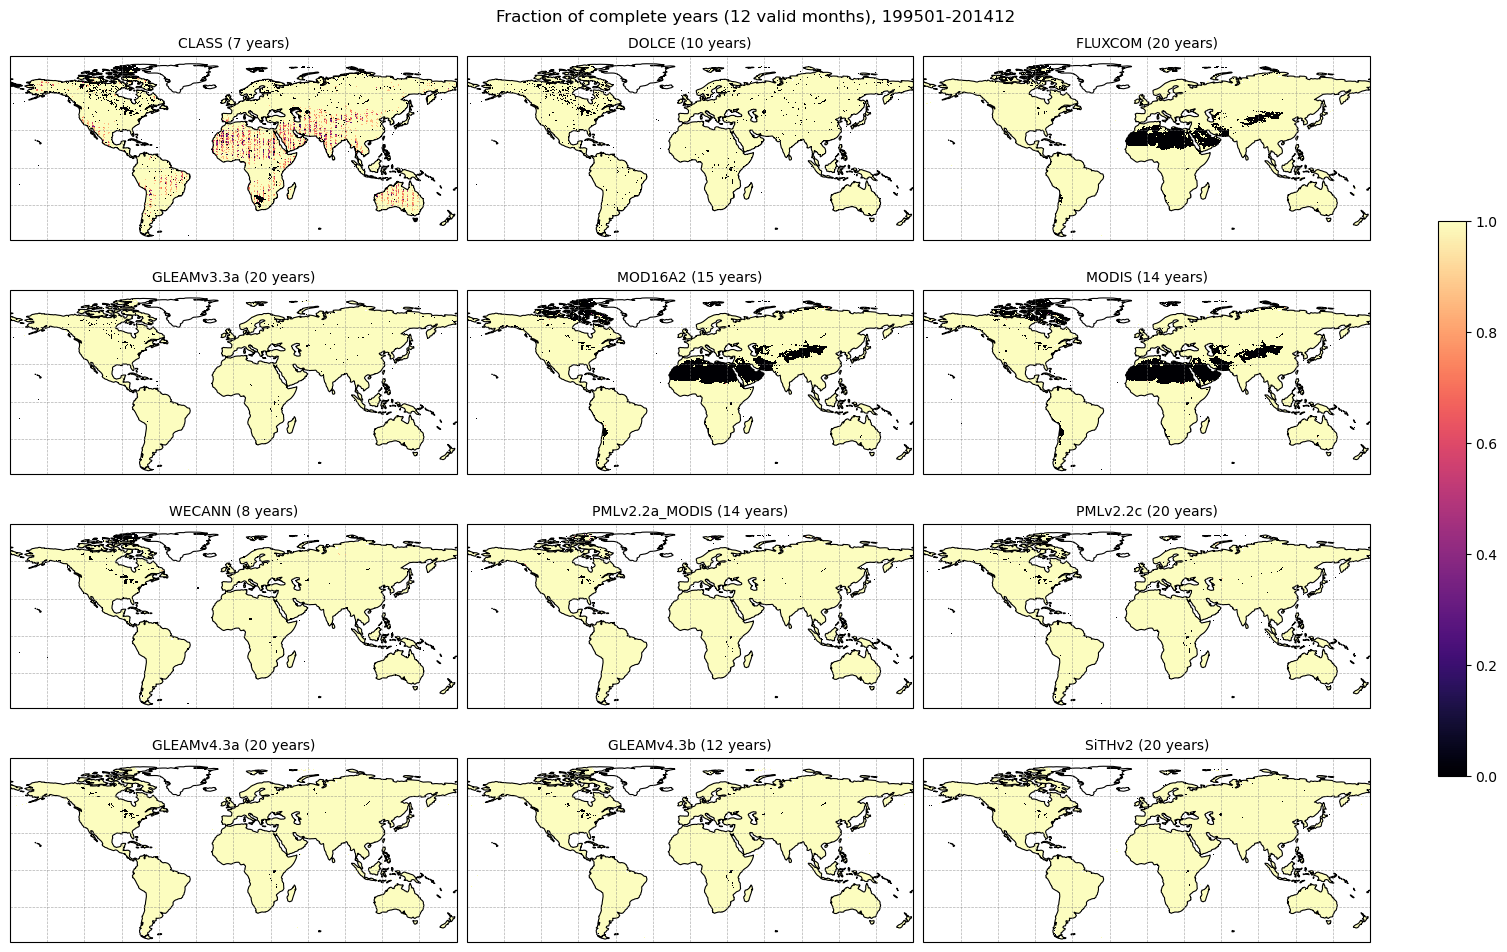

In [ ]:
def map_panels(fields: dict, title: str, ncols: int = 3, **kwargs):
    """One map per product (dict of (lat, lon) fields), sharing a colorbar."""
    fig, axs = plotting.facets(len(fields), ncols=ncols, maps=True, panel_size=(5.0, 2.4))
    for ax, (label, da) in zip(axs, fields.items()):
        im = da.plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, **kwargs)
        ax.set_title(label, fontsize=10)
        plotting.map_ax(ax, cfg.LAT_BNDS)
    fig.colorbar(im, ax=axs, shrink=0.6)
    fig.suptitle(title)
    plt.show()


# Months of each product's record inside TIME_SLICE
n_months = {p: int(cov[p].zonal_area.sel(time=TIME_SLICE).sizes["time"]) for p in PRODUCTS}
frac_months = {f"{p} ({n_months[p]} months)": (cov[p].n_valid_months / n_months[p]).where(land[p])
               for p in PRODUCTS if n_months[p] > 0}
map_panels(frac_months, f"Fraction of months with valid ET, {PERIOD}", vmin=0, vmax=1, cmap="magma")

frac_years = {f"{p} ({n_years[p]} years)": (cov[p].n_complete_years / n_years[p]).where(land[p]) for p in IN_SLICE}
map_panels(frac_years, f"Fraction of complete years (12 valid months), {PERIOD}", vmin=0, vmax=1, cmap="magma")

Valid fraction of the land area in each latitude row, by month over each product's full record, and by calendar
month over `TIME_SLICE` (seasonal gaps, e.g. in winter at high latitudes).

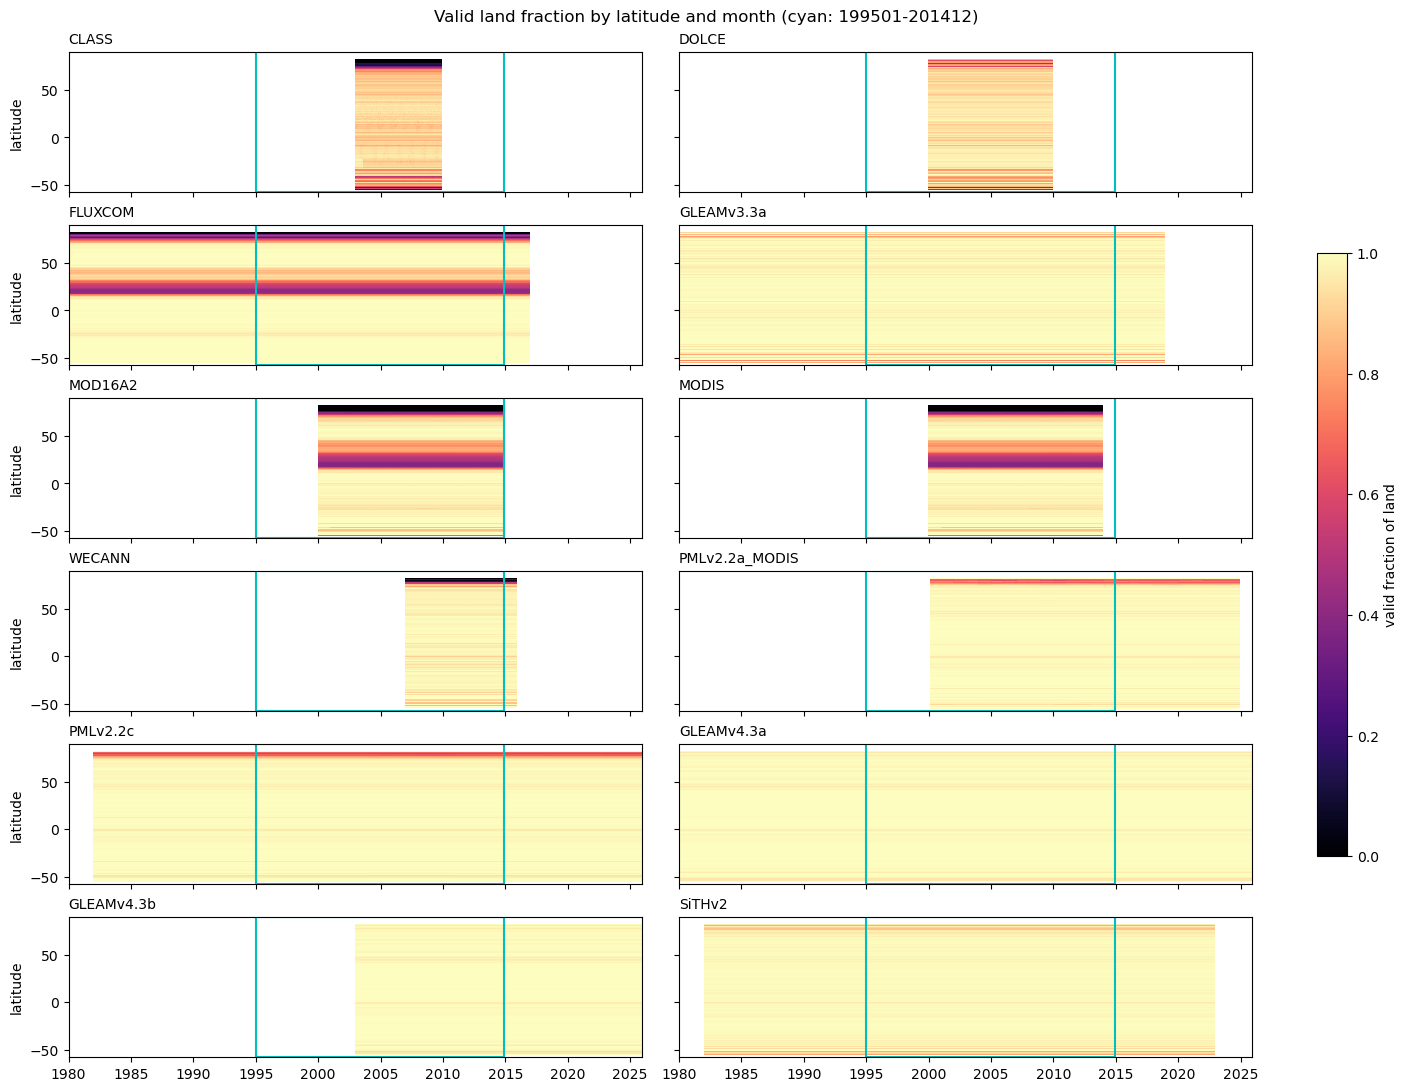

In [ ]:
# Fraction of the land area of each latitude row with valid data, per month
zonal_frac = {
    p: (cov[p].zonal_area / area[p].sum("lon")).where(area[p].sum("lon") > 0)
    for p in PRODUCTS
}
months = pd.concat([pd.Series(zonal_frac[p].time.values) for p in PRODUCTS])
t0, t1 = months.min(), months.max()

ncols = 2
nrows = int(np.ceil(len(PRODUCTS) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(14, 1.8 * nrows), sharex=True, sharey=True, layout="constrained")
for ax, p in zip(axs.flat, PRODUCTS):
    z = zonal_frac[p]
    im = ax.pcolormesh(z.time, z.lat, z.T, vmin=0, vmax=1, cmap="magma", shading="nearest")
    ax.axvspan(pd.Timestamp(TIME_SLICE.start), pd.Timestamp(TIME_SLICE.stop), facecolor="none", edgecolor="c", lw=1.5)
    ax.set_title(p, loc="left", fontsize=10)
    ax.set_xlim(t0, t1)
for ax in axs[:, 0]:
    ax.set_ylabel("latitude")
for ax in axs.flat[len(PRODUCTS):]:
    ax.remove()
fig.colorbar(im, ax=axs, shrink=0.6, label="valid fraction of land")
fig.suptitle(f"Valid land fraction by latitude and month (cyan: {PERIOD})")
plt.show()

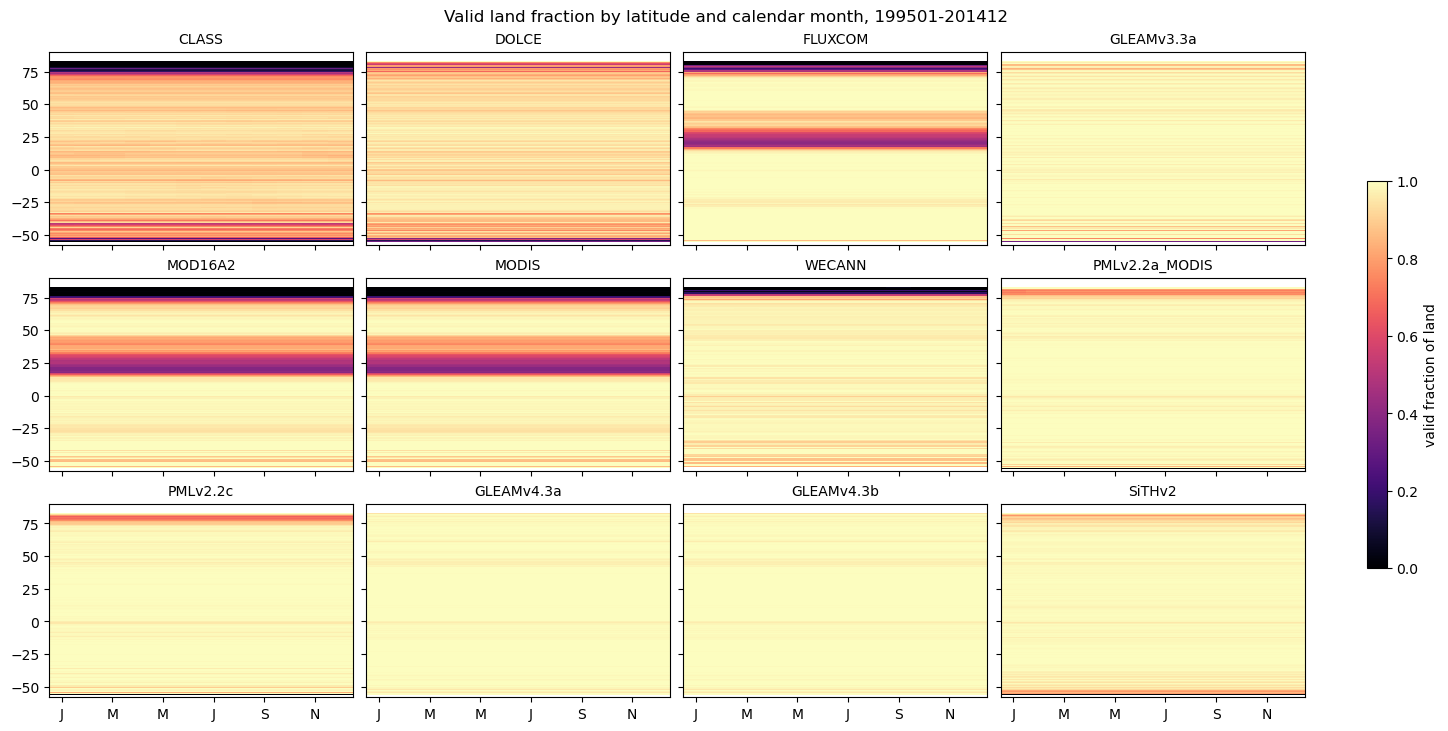

In [ ]:
# Mean over the years in TIME_SLICE of the valid fraction of each latitude row, by calendar month
fig, axs = plotting.facets(len(IN_SLICE), ncols=4, panel_size=(3.6, 2.4), sharex=True, sharey=True)
for ax, p in zip(axs, IN_SLICE):
    z = zonal_frac[p].sel(time=TIME_SLICE).groupby("time.month").mean()
    im = ax.pcolormesh(z.month, z.lat, z.T, vmin=0, vmax=1, cmap="magma", shading="nearest")
    ax.set_title(p, fontsize=10)
    ax.set_xticks(range(1, 13, 2), ["J", "M", "M", "J", "S", "N"])
fig.colorbar(im, ax=axs, shrink=0.6, label="valid fraction of land")
fig.suptitle(f"Valid land fraction by latitude and calendar month, {PERIOD}")
plt.show()

## 3. Timeseries of global and regional area-weighted averages

Monthly valid land area (as a fraction of the region's land) and area-weighted mean ET over the valid land of
each product. The mean ET of a month covers only that month's valid land, so a product's gaps (e.g. in winter at
high latitudes, where ET is low) bias its regional means. The last figure removes this effect by comparing each
product with `REF_ET` on the target grid over the cells valid in both in each month.

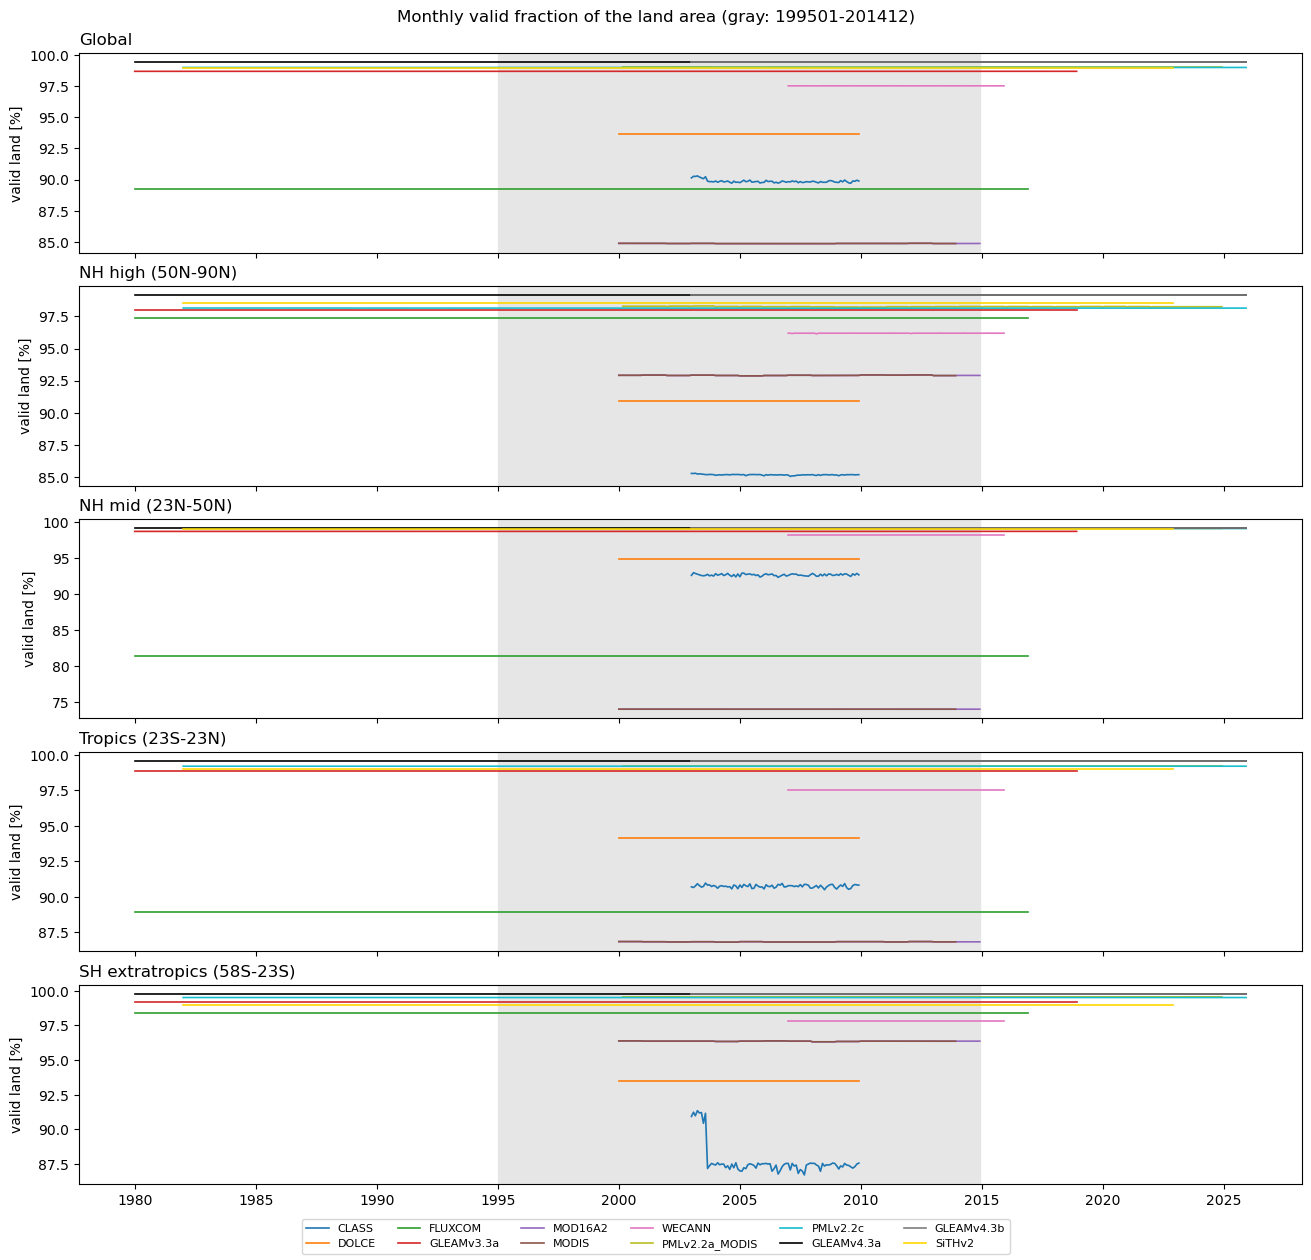

In [ ]:
# Zonal sums over land, so each latitude band only needs a sum over lat: valid land area and area-weighted ET
zonal_land = {p: area[p].sum("lon") for p in PRODUCTS}

cover, mean_et = {}, {}
for r, b in REGIONS.items():
    band = lambda zonal: zonal.sel(lat=b).sum("lat")
    cover[r] = {p: band(cov[p].zonal_area) / band(zonal_land[p]) for p in PRODUCTS}
    mean_et[r] = {p: (band(cov[p].zonal_et) / band(cov[p].zonal_area)).where(band(cov[p].zonal_area) > 0)
                  for p in PRODUCTS}


def annual(ts: xr.DataArray) -> xr.DataArray:
    """Calendar-year mean of a monthly series, only for years with 12 valid months, stamped mid-year."""
    ann = ts.groupby("time.year").mean().where(ts.notnull().groupby("time.year").sum() == 12)
    return ann.assign_coords(year=pd.to_datetime([f"{y}-07-01" for y in ann.year.values])).rename(year="time")


def plot_regions(series: dict, ylabel: str, title: str, annual_mean: bool = False, zero_line: bool = False):
    """One panel per region; one line per product, monthly (thin) and optionally annual means (thick)."""
    fig, axs = plt.subplots(len(series), 1, figsize=(13, 2.5 * len(series)), sharex=True, layout="constrained")
    for ax, (r, by_product) in zip(axs, series.items()):
        for p, ts in by_product.items():
            ax.plot(ts.time, ts, color=COLORS[p], lw=0.6 if annual_mean else 1.2, alpha=0.4 if annual_mean else 1,
                    label=None if annual_mean else p)
            if annual_mean:
                ann = annual(ts)
                ax.plot(ann.time, ann, color=COLORS[p], lw=1.8, marker="o", ms=2.5, label=p)
        ax.axvspan(pd.Timestamp(TIME_SLICE.start), pd.Timestamp(TIME_SLICE.stop), color="0.9", zorder=0)
        if zero_line:
            ax.axhline(0, color="gray", lw=0.8)
        ax.set_title(r, loc="left")
        ax.set_ylabel(ylabel)
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncols=6, fontsize=8)
    fig.suptitle(title)
    plt.show()


plot_regions({r: {p: 100 * ts for p, ts in c.items()} for r, c in cover.items()}, "valid land [%]",
             f"Monthly valid fraction of the land area (gray: {PERIOD})")

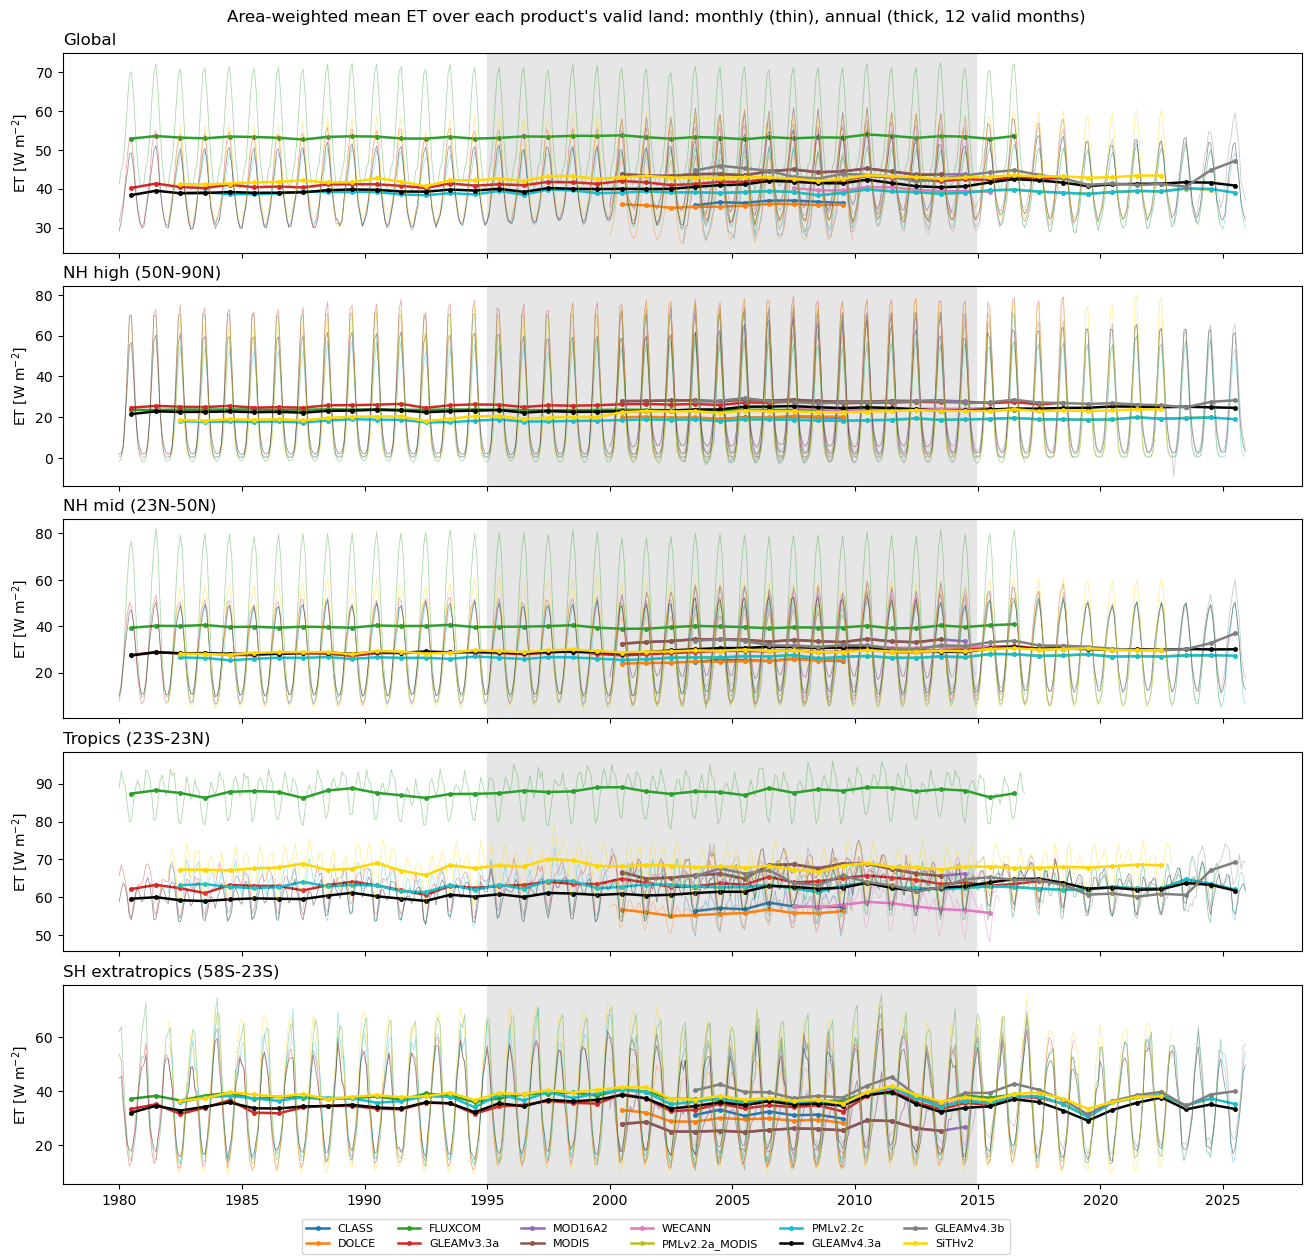

In [ ]:
plot_regions(mean_et, "ET [W m$^{-2}$]",
             "Area-weighted mean ET over each product's valid land: monthly (thin), annual (thick, 12 valid months)",
             annual_mean=True)

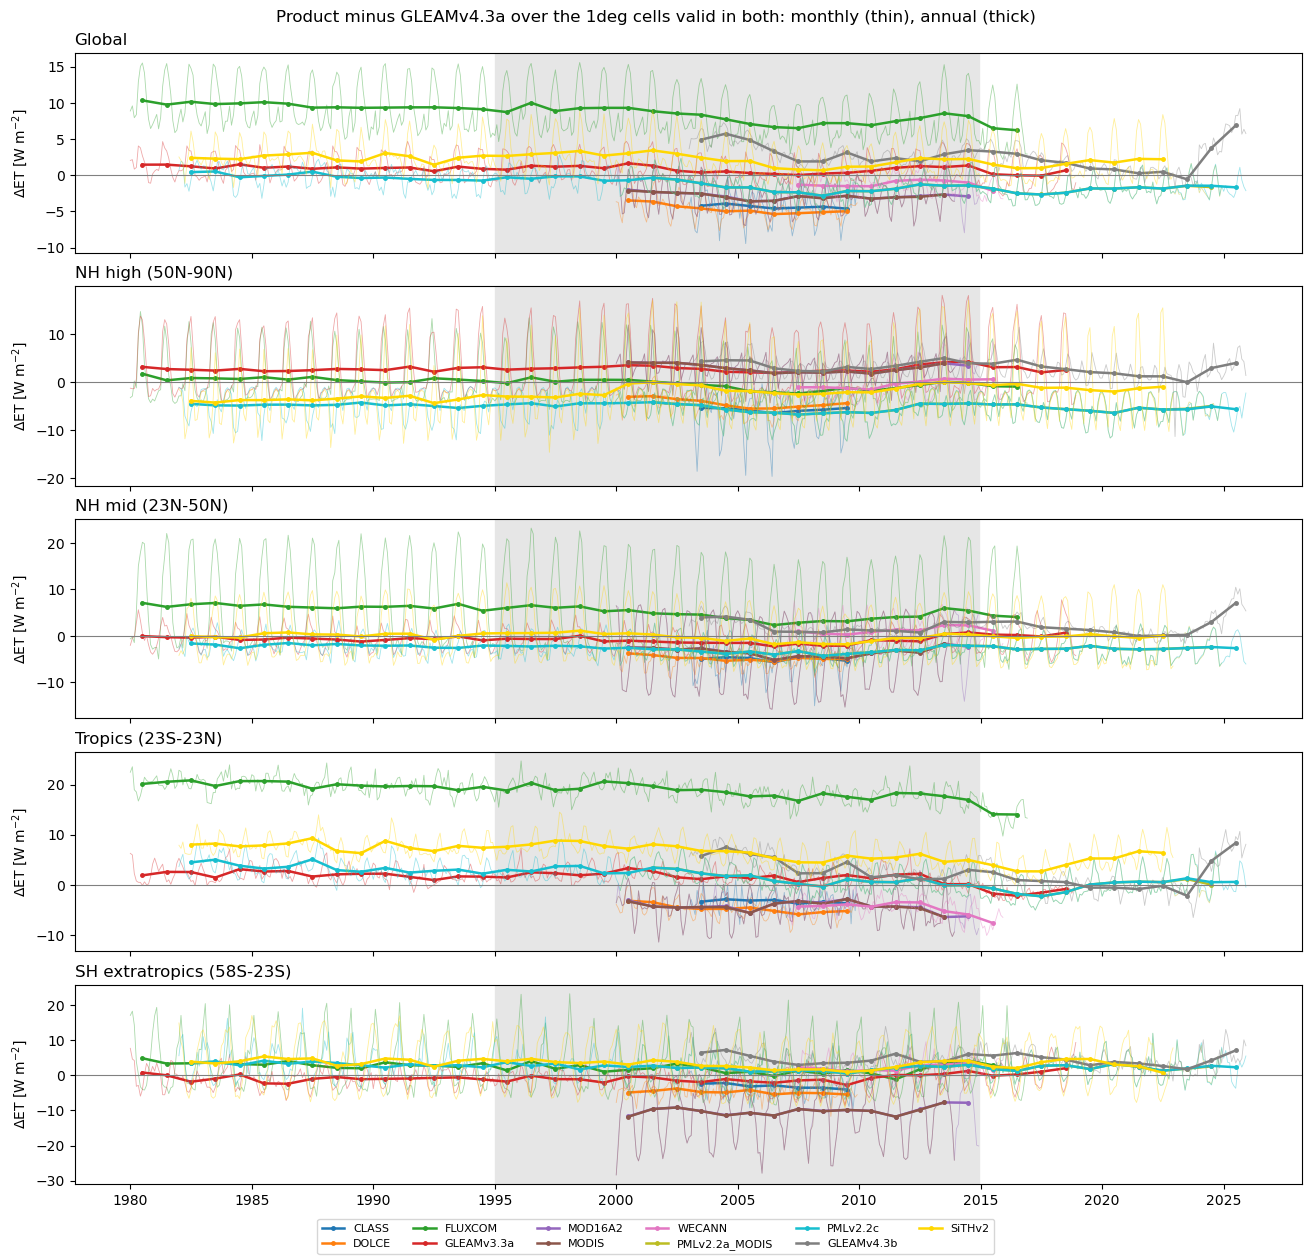

In [ ]:
# Product minus REF_ET, area-weighted over the target cells valid in both in each month
others = [p for p in PRODUCTS if p != REF_ET]
diff_et = {r: {} for r in REGIONS}
for p in others:
    a, c = xr.align(mon1[p], mon1[REF_ET], join="inner")  # months in both records
    w = land_area1.where(a.notnull() & c.notnull(), 0)
    for r, b in REGIONS.items():
        wb = w.sel(lat=b)
        diff_et[r][p] = (((a - c).sel(lat=b) * wb).sum(["lat", "lon"]) / wb.sum(["lat", "lon"])).where(wb.sum(["lat", "lon"]) > 0)

plot_regions(diff_et, "$\\Delta$ET [W m$^{-2}$]",
             f"Product minus {REF_ET} over the {rg.grid_tag(TARGET_RES)} cells valid in both: monthly (thin), annual (thick)",
             annual_mean=True, zero_line=True)

## 4. Climatological ET

Climatological ET on the target grid as the pipeline computes it (`clim1`, over each product's complete years in
`TIME_SLICE`), its zonal mean, and the mean difference from `REF_ET` over the years in which both have a complete
year.

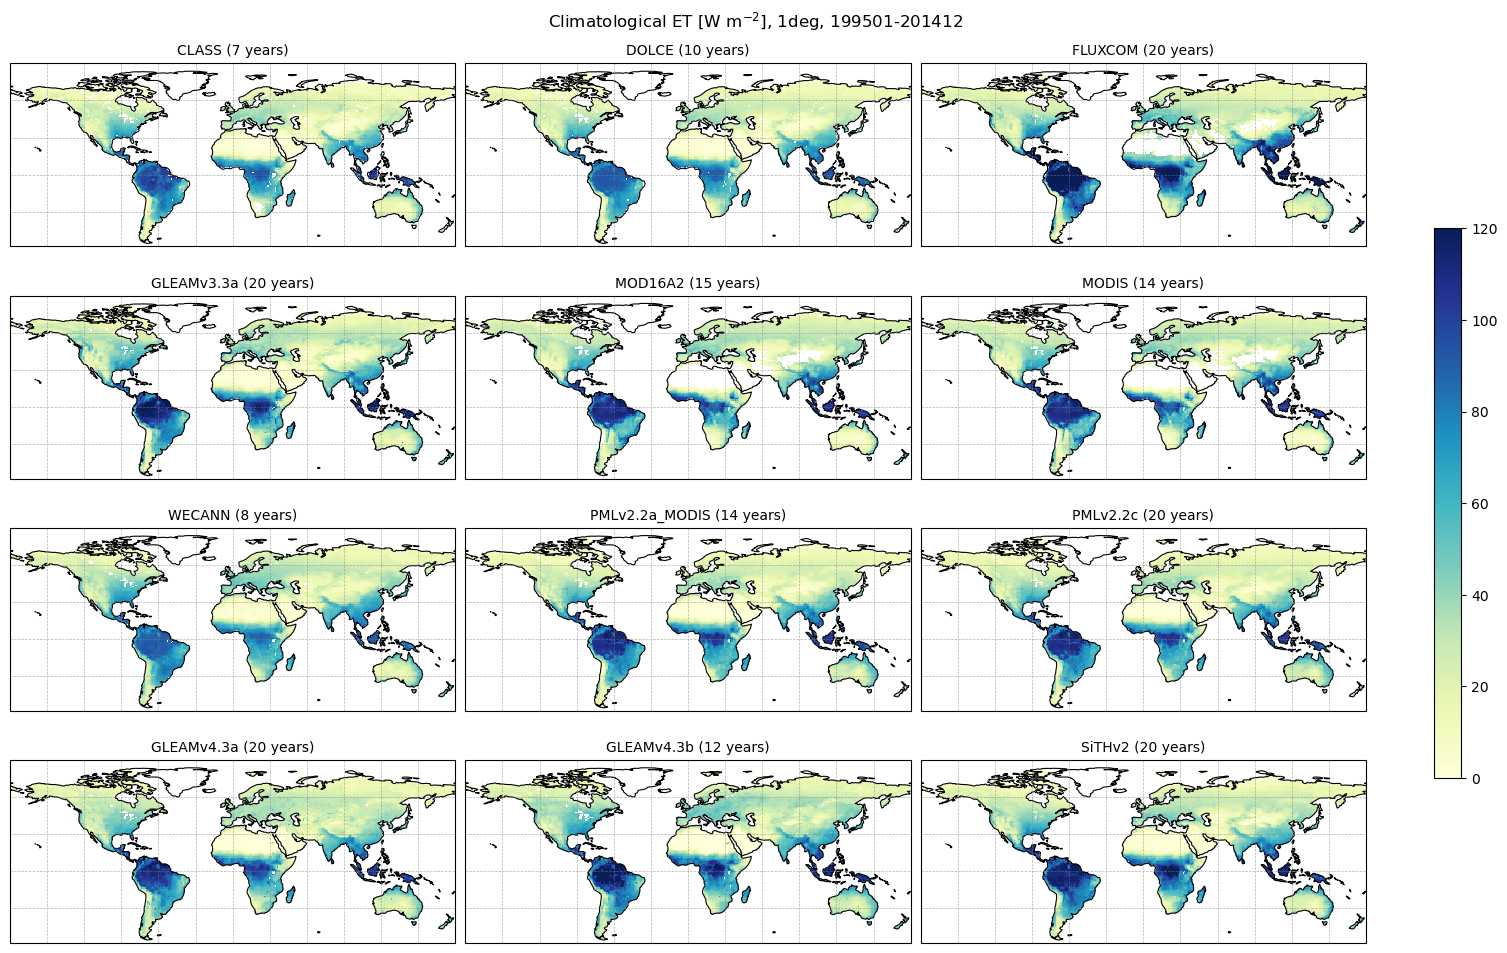

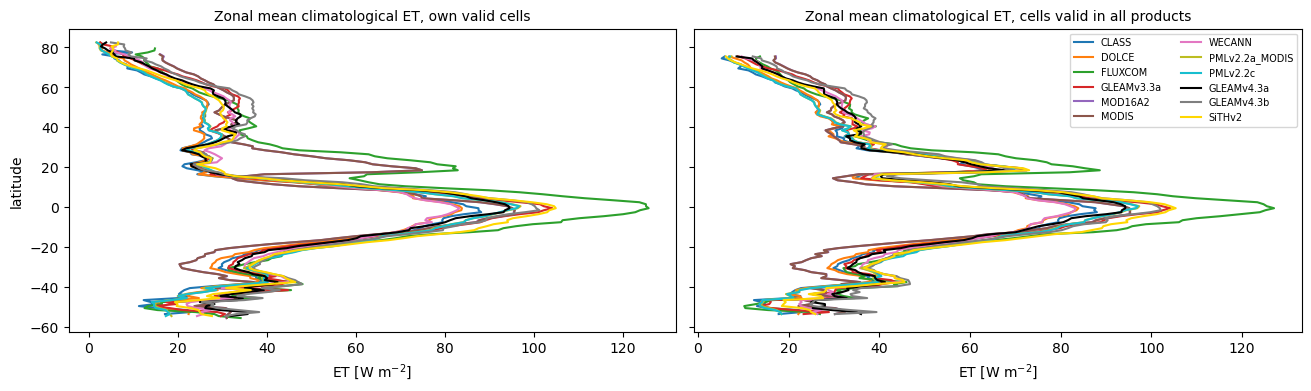

,years,own valid cells,cells valid in all
"global mean ET [W m-2], 199501-201412",,,
CLASS,7,36.3,41.7
DOLCE,10,35.6,41.0
FLUXCOM,20,52.8,53.9
GLEAMv3.3a,20,41.2,46.7
MOD16A2,15,43.4,43.0
MODIS,14,43.4,43.0
WECANN,8,39.8,45.0
PMLv2.2a_MODIS,14,39.0,44.9
PMLv2.2c,20,39.0,44.9


In [ ]:
map_panels({f"{p} ({n_years[p]} years)": clim1[p] for p in IN_SLICE},
           f"Climatological ET [W m$^{{-2}}$], {rg.grid_tag(TARGET_RES)}, {PERIOD}", vmin=0, vmax=120, cmap="YlGnBu")


def area_mean(da: xr.DataArray, mask: xr.DataArray, dims) -> xr.DataArray:
    """Land-area-weighted mean of `da` over `dims`, on the cells of `mask`."""
    w = land_area1.where(mask & da.notnull(), 0)
    return (da.fillna(0) * w).sum(dims) / w.sum(dims)


# Global mean and zonal mean of the climatology, on each product's own valid cells and on the cells valid in all
common1 = valid1["all products"]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True, layout="constrained")
for ax, kind in zip(axs, ["own valid cells", "cells valid in all products"]):
    for p in IN_SLICE:
        mask = valid1[p] if kind == "own valid cells" else common1
        ax.plot(area_mean(clim1[p], mask, "lon"), clim1[p].lat, color=COLORS[p], label=p)
    ax.set_xlabel("ET [W m$^{-2}$]")
    ax.set_title(f"Zonal mean climatological ET, {kind}", fontsize=10)
axs[0].set_ylabel("latitude")
axs[1].legend(fontsize=7, ncols=2)
plt.show()

pd.DataFrame({
    "years": {p: n_years[p] for p in IN_SLICE},
    "own valid cells": {p: float(area_mean(clim1[p], valid1[p], ["lat", "lon"])) for p in IN_SLICE},
    "cells valid in all": {p: float(area_mean(clim1[p], common1, ["lat", "lon"])) for p in IN_SLICE},
}).round(1).rename_axis(f"global mean ET [W m-2], {PERIOD}")

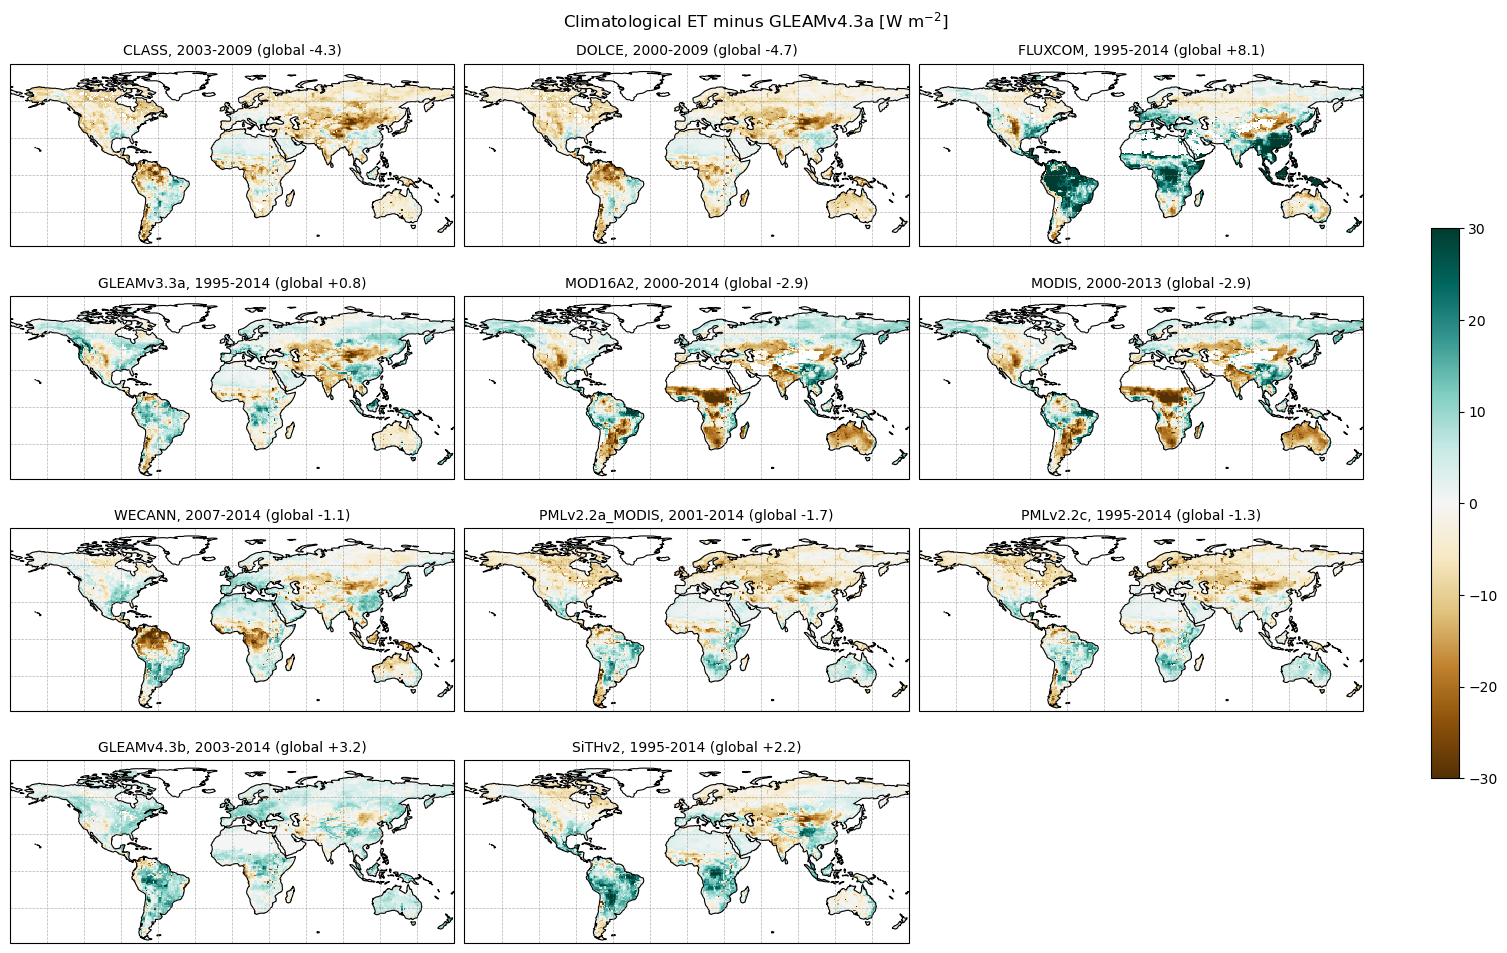

In [ ]:
diff_clim = {}
for p in [p for p in IN_SLICE if p != REF_ET]:
    a, c = xr.align(ann1[p], ann1[REF_ET], join="inner")  # shared years
    if a.sizes["year"] == 0:
        continue
    # Mean over the years in which both are valid, so both cover the same years in each cell
    d = (a - c).mean("year")
    years = f"{int(a.year.min())}-{int(a.year.max())}"
    diff_clim[f"{p}, {years} (global {float(area_mean(d, d.notnull(), ['lat', 'lon'])):+.1f})"] = d
map_panels(diff_clim, f"Climatological ET minus {REF_ET} [W m$^{{-2}}$]", vmin=-30, vmax=30, cmap="BrBG")